# Exercise: Full Fine-Tuning BERT

*Course Exercise 3, completed and extended. Part 2 of 3 in the series on adapting a pre-trained encoder: [4](4-create-a-bert-sentiment-classifier.ipynb) → **4.1** → [4.2](4.2-linear-probe-vs-full-fine-tuning-vs-lora.ipynb).*

**What this notebook does.** I take the same DistilBERT encoder as in [notebook 4](4-create-a-bert-sentiment-classifier.ipynb), but this time nothing is frozen: all 67M parameters are updated to classify SMS messages as spam or not spam.

**What changed from notebook 4, and why it matters.**

| | Notebook 4 | This notebook |
|---|---|---|
| Trainable parameters | 592,130 (0.88%) | 66,955,010 (100%) |
| What the optimizer can change | Only how features are *read* | The features themselves |
| Learning rate | $2\times10^{-3}$ | $2\times10^{-5}$ |
| Dataset | IMDB reviews, balanced, long | SMS spam, 13% positive, short |
| The right headline metric | Accuracy | Not accuracy |

The last row is the part I want to be careful about. The exercise asks "what do you think the evaluation accuracy will be?", and the model does score close to 99%. But on this dataset a model that never predicts spam scores 87%, and a bag-of-words model gets to 98%. A result only means something relative to its baselines, so I build those first.

**The headline finding** is not the one the exercise sets up. Full fine-tuning works, but on this task it does not beat a 769-parameter linear probe on the frozen backbone, and under a paired test it is not clearly better than the bag of words either. Sections 7 and 8 show why.

**Outline**

1. The task, the class imbalance, and what a trivial model scores
2. A classical baseline: TF-IDF + logistic regression
3. Math deep dive: what full fine-tuning optimizes, how gradients reach layer 1, and why the learning rate drops 100x
4. Training
5. Evaluation under class imbalance: precision, recall, MCC, PR curves, and choosing a threshold from costs
6. What fine-tuning did to the model: representation geometry before and after, and which layers moved
7. How spam and abuse classifiers are built in production
8. Limitations and what comes next

In [1]:
import logging
import time
import warnings

warnings.filterwarnings("ignore")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from matplotlib.colors import LinearSegmentedColormap

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
transformers.set_seed(42)

# One plotting style for the whole notebook
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, SECONDARY, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#2a78d6", "#0d366b"])

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 110,
        "savefig.dpi": 160,
        "savefig.bbox": "tight",
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": SECONDARY,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "text.color": INK,
        "lines.linewidth": 2,
        "legend.frameon": False,
    }
)

print(f"torch {torch.__version__} | transformers {transformers.__version__}")

torch 2.14.1 | transformers 5.19.0


## 1. The task and the data

The [SMS Spam Collection](https://huggingface.co/datasets/ucirvine/sms_spam) (Almeida, Gómez Hidalgo & Yamakami, 2011) contains 5,574 real text messages labelled `ham` (0, not spam) or `spam` (1). It ships as a single split, so I hold out 20% as a test set with a fixed seed.

The original course notebook pins `datasets==2.15.0` in its first cell. I leave that out: the environment in [`requirements.txt`](requirements.txt) uses a current release, where the dataset id needs its namespace (`ucirvine/sms_spam`).

In [2]:
# Load the sms_spam dataset
# See: https://huggingface.co/datasets/ucirvine/sms_spam

import datasets
from datasets import load_dataset

datasets.disable_progress_bars()

# The sms_spam dataset only has a train split, so we use the train_test_split method to split it into train and test
dataset = load_dataset("ucirvine/sms_spam", split="train").train_test_split(
    test_size=0.2, shuffle=True, seed=23
)

splits = ["train", "test"]

# View the dataset characteristics
dataset["train"]

Dataset({
    features: ['sms', 'label'],
    num_rows: 4459
})

Let's look at the first example!

In [3]:
# Inspect the first example. Do you think this is spam or not?
dataset["train"][0]

{'sms': 'Had your mobile 10 mths? Update to the latest Camera/Video phones for FREE. KEEP UR SAME NUMBER, Get extra free mins/texts. Text YES for a call\n',
 'label': 1}

### 1.1 Class imbalance changes what "good" means

Let $\pi = \Pr(y = \text{spam})$. The classifier that always answers "not spam" has accuracy $1 - \pi$ and catches no spam at all. Any accuracy figure has to be read against that floor, and accuracy alone can never show whether the minority class is being found.

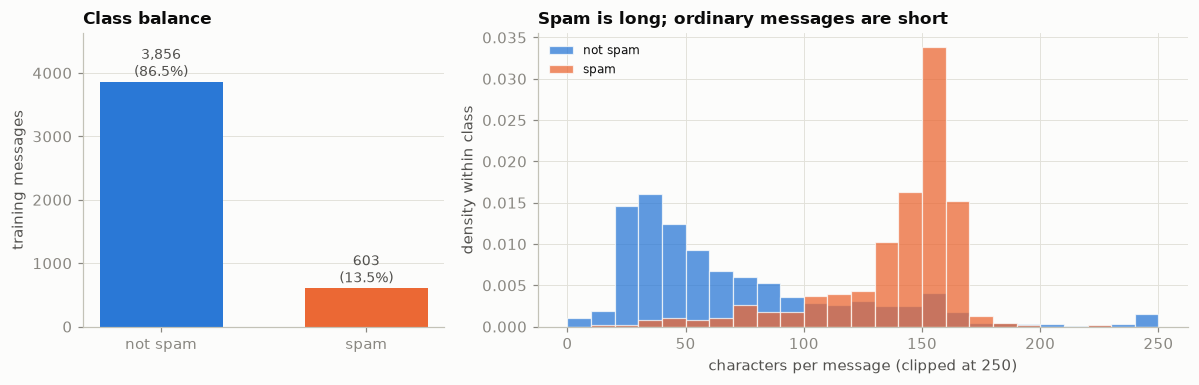

train: 4,459 messages, 13.5% spam
test : 1,115 messages, 12.9% spam
accuracy of always predicting 'not spam' on the test set: 0.871


In [4]:
# Figure 1: class balance and message length
y_train = np.array(dataset["train"]["label"])
y_test = np.array(dataset["test"]["label"])
train_text, test_text = list(dataset["train"]["sms"]), list(dataset["test"]["sms"])
char_len = np.array([len(t) for t in train_text])

spam_rate = y_test.mean()
majority_accuracy = 1 - spam_rate

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.8]})

counts = [int((y_train == 0).sum()), int((y_train == 1).sum())]
bars = ax1.bar(["not spam", "spam"], counts, color=[BLUE, ORANGE], width=0.6)
for bar, c in zip(bars, counts):
    ax1.annotate(f"{c:,}\n({c / len(y_train):.1%})", xy=(bar.get_x() + bar.get_width() / 2, c), xytext=(0, 4),
                 textcoords="offset points", ha="center", color=SECONDARY, fontsize=9)
ax1.set(ylabel="training messages", title="Class balance", ylim=(0, max(counts) * 1.2))
ax1.grid(axis="x", visible=False)

bins = np.arange(0, 260, 10)
for cls, color, name in [(0, BLUE, "not spam"), (1, ORANGE, "spam")]:
    ax2.hist(np.clip(char_len[y_train == cls], 0, 250), bins=bins, density=True, color=color, alpha=0.75,
             edgecolor=SURFACE, linewidth=0.8, label=name)
ax2.set(xlabel="characters per message (clipped at 250)", ylabel="density within class", title="Spam is long; ordinary messages are short")
ax2.legend(loc="upper left", fontsize=8)

fig.tight_layout()
fig.savefig("assets/4.1-class-balance.png")
plt.show()

print(f"train: {len(y_train):,} messages, {y_train.mean():.1%} spam")
print(f"test : {len(y_test):,} messages, {spam_rate:.1%} spam")
print(f"accuracy of always predicting 'not spam' on the test set: {majority_accuracy:.3f}")

The right panel already contains most of a spam filter. Spam messages cluster near the old 160-character SMS limit because senders pack in as much as one message allows, while ordinary messages are short. A single threshold on length would do far better than chance. Any model I train has to beat cheap signals like this one to justify its cost.

## 2. A classical baseline: TF-IDF + logistic regression

Before spending 67M parameters, it is worth knowing what a few thousand get.

**TF-IDF** represents a message $d$ as a sparse vector with one entry per vocabulary term $t$:

$$\mathrm{tfidf}(t, d) = \mathrm{tf}(t, d)\cdot\left(\ln\frac{1 + N}{1 + \mathrm{df}(t)} + 1\right),$$

where $\mathrm{tf}$ is the count of $t$ in $d$, $\mathrm{df}(t)$ the number of messages containing $t$, and $N$ the number of messages. Each vector is then scaled to unit length. Words that appear everywhere get little weight; words concentrated in a few messages get a lot.

This is the recipe from [notebook 4, section 1.4](4-create-a-bert-sentiment-classifier.ipynb) with a hand-designed, non-learned $\phi$: a bag of words has no notion of order or context. Logistic regression on top is the same convex problem as the linear probe.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    matthews_corrcoef,
    precision_recall_curve,
    precision_recall_fscore_support,
)
from sklearn.pipeline import make_pipeline


def summarize(name, y_true, y_pred, trainable):
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", zero_division=0)
    return {
        "model": name,
        "trainable parameters": trainable,
        "accuracy": (y_true == y_pred).mean(),
        "spam precision": precision,
        "spam recall": recall,
        "spam F1": f1,
        "MCC": matthews_corrcoef(y_true, y_pred),
    }


tfidf_model = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    LogisticRegression(C=10, max_iter=2000),
)
tfidf_model.fit(train_text, y_train)
tfidf_scores = tfidf_model.predict_proba(test_text)[:, 1]
tfidf_preds = (tfidf_scores >= 0.5).astype(int)
n_tfidf_features = len(tfidf_model[0].vocabulary_)

results = [
    summarize("always 'not spam'", y_test, np.zeros_like(y_test), 0),
    summarize("TF-IDF + logistic regression", y_test, tfidf_preds, n_tfidf_features + 1),
]


def show(results):
    table = pd.DataFrame(results).set_index("model").round(3)
    table["trainable parameters"] = table["trainable parameters"].map("{:,}".format)
    return table


show(results)

,trainable parameters,accuracy,spam precision,spam recall,spam F1,MCC
model,,,,,,
always 'not spam',0,0.871,0.000,0.000,0.000,0.000
TF-IDF + logistic regression,"12,080",0.981,0.984,0.868,0.923,0.914


The baseline is strong. That is the honest starting point for this notebook: the question is not whether a transformer can classify spam, but what it buys over a model that trains in a fraction of a second.

## 3. Pre-process the datasets

Now we are going to process our datasets by converting all the text into tokens for our models. The mechanics (WordPiece, `[CLS]`, truncation, dynamic padding) are covered in [notebook 4, section 3](4-create-a-bert-sentiment-classifier.ipynb). SMS messages are short, so truncation never applies here.

In [6]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("distilbert/distilbert-base-uncased")

# Let's use a lambda function to tokenize all the examples
tokenized_dataset = {}
for split in splits:
    tokenized_dataset[split] = dataset[split].map(
        lambda x: tokenizer(x["sms"], truncation=True), batched=True
    )

token_lengths = [len(ids) for ids in tokenized_dataset["train"]["input_ids"]]
print(f"tokens per message: median {np.median(token_lengths):.0f}, 99th percentile {np.percentile(token_lengths, 99):.0f}, max {max(token_lengths)}")

# Inspect the available columns in the dataset
tokenized_dataset["train"]

tokens per message: median 20, 99th percentile 78, max 238


Dataset({
    features: ['sms', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 4459
})

## 4. Load and set up the model

In this case we are doing a full fine-tuning, so we will want to unfreeze all parameters.

A detail worth knowing: `from_pretrained` returns a model whose parameters *already* have `requires_grad=True`, so the loop below changes nothing. It is there to make the intent explicit and to contrast with notebook 4, where the same loop set the flag to `False` on the backbone.

In [7]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert/distilbert-base-uncased",
    num_labels=2,
    id2label={0: "not spam", 1: "spam"},
    label2id={"not spam": 0, "spam": 1},
    # PyTorch's fused (SDPA) attention does not support dropout on Apple Silicon (MPS)
    attn_implementation="eager",
)

# Unfreeze all the model parameters.
# Hint: Check the documentation at https://huggingface.co/docs/transformers/v4.36.1/en/training
for param in model.parameters():
    param.requires_grad = True

total = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable parameters: {trainable:,} of {total:,} ({trainable / total:.0%})")

trainable parameters: 66,955,010 of 66,955,010 (100%)


In [8]:
print(model)

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

### 4.1 Snapshot the model before training

To see what fine-tuning *does*, I need a "before". I keep a copy of the pre-trained weights and extract the `[CLS]` vector of every message from the untouched backbone. Those cached features also give one more baseline for free: the frozen-backbone linear probe from notebook 4, applied to this task.

In [9]:
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

collator = DataCollatorWithPadding(tokenizer=tokenizer)
device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
model.to(device)


@torch.no_grad()
def cls_features(dataset, batch_size=64):
    """Return the backbone's final [CLS] vector for every example."""
    model.eval()
    loader = DataLoader(dataset.remove_columns(["sms", "label"]), batch_size=batch_size, collate_fn=collator)
    features = []
    for batch in loader:
        batch = {k: v.to(model.device) for k, v in batch.items()}
        features.append(model.distilbert(**batch).last_hidden_state[:, 0].cpu())
    return torch.cat(features).numpy()


initial_state = {name: p.detach().cpu().clone() for name, p in model.named_parameters()}
features_before = {split: cls_features(tokenized_dataset[split]) for split in splits}

# Frozen-backbone linear probe (the notebook 4 recipe) as a third baseline
probe = make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=5000))
probe.fit(features_before["train"], y_train)
probe_preds = probe.predict(features_before["test"])
probe_scores = probe.predict_proba(features_before["test"])[:, 1]
results.append(summarize("frozen DistilBERT + linear probe", y_test, probe_preds, 768 + 1))

show(results)

,trainable parameters,accuracy,spam precision,spam recall,spam F1,MCC
model,,,,,,
always 'not spam',0,0.871,0.000,0.000,0.000,0.000
TF-IDF + logistic regression,"12,080",0.981,0.984,0.868,0.923,0.914
frozen DistilBERT + linear probe,769,0.993,0.993,0.951,0.972,0.968


## 5. Math deep dive: what full fine-tuning optimizes

### 5.1 The objective

In notebook 4 the backbone was a constant and only the head was optimized. Now the whole parameter vector moves, starting from the pre-trained point:

$$\min_{\theta_b,\,\theta_h}\; \frac{1}{n}\sum_{i=1}^{n} -\log p_{\theta_h}\!\big(y_i \mid \phi_{\theta_b}(x_i)\big), \qquad \theta_b^{(0)} = \theta_b^{\text{pre-trained}},\quad \theta_h^{(0)} \sim \text{random}.$$

The loss function is identical. What changes is that $\phi$ is now a function of trainable parameters, so the optimizer can move the features to where the task needs them and is no longer limited to drawing a hyperplane through wherever pre-training left them.

Pre-training enters only through the starting point. There is no explicit term keeping $\theta_b$ near $\theta_b^{(0)}$; the only things holding it there are a small learning rate and a small number of steps.

### 5.2 How the gradient reaches the first layer

From notebook 4, the error signal at the logits is $\boldsymbol\delta_z = \mathbf{p} - \mathbf{y}$, and what flows into the encoder is $\partial\mathcal{L}/\partial\mathbf{h} = W^\top(\mathbf{p} - \mathbf{y})$. Previously that was discarded. Now it is propagated through all six blocks by the chain rule. Each block has the residual form

$$\mathbf{x}^{(l+1)} = \mathrm{LN}\big(\mathbf{x}^{(l)} + F_l(\mathbf{x}^{(l)})\big) \quad\Longrightarrow\quad \frac{\partial \mathbf{x}^{(l+1)}}{\partial \mathbf{x}^{(l)}} = J_{\mathrm{LN}}\left(I + \frac{\partial F_l}{\partial \mathbf{x}^{(l)}}\right),$$

so the gradient at layer $l$ is a product of terms that each contain an identity:

$$\frac{\partial \mathcal{L}}{\partial \mathbf{x}^{(l)}} = \frac{\partial \mathcal{L}}{\partial \mathbf{x}^{(L)}}\prod_{k=l}^{L-1} J_{\mathrm{LN}}^{(k)}\left(I + \frac{\partial F_k}{\partial \mathbf{x}^{(k)}}\right).$$

The identity path is what lets a useful signal reach the embeddings without vanishing. Note that only the `[CLS]` position receives a gradient directly from the loss. Every other token is trained only through its influence on `[CLS]` via attention.

### 5.3 What it costs

| | Frozen backbone | Full fine-tuning |
|---|---|---|
| Forward pass | Full encoder | Full encoder |
| Backward pass | Head only | Full encoder (roughly doubles the compute per step) |
| Activations kept in memory | None from the encoder | All of them, $O(B \cdot n \cdot d \cdot L)$ |
| Optimizer state (AdamW keeps $\mathbf m$, $\mathbf v$) | 2 × 0.59M values | 2 × 67M values |
| Storage per task | 2.4 MB head | 268 MB full model |
| Can features be cached? | Yes | No, they change every step |

The storage row is the one that hurts at scale: a hundred tasks means a hundred full copies of the model. That is the problem adapters and LoRA were invented to solve, and it is where [notebook 4.2](4.2-linear-probe-vs-full-fine-tuning-vs-lora.ipynb) goes.

### 5.4 Why the learning rate drops by 100x

In notebook 4 I used $\eta = 2\times10^{-3}$. Here I use $2\times10^{-5}$. The reason is the asymmetry between the two parts of the model:

- $\theta_h$ is random. Large steps are harmless because there is nothing to lose.
- $\theta_b$ encodes everything DistilBERT learned from billions of words. A large step in the direction of the gradient of 16 text messages overwrites that with noise. This is **catastrophic forgetting** (Kirkpatrick et al., 2016): a network trained on a new task loses what it knew about the old one because nothing in the new objective protects it.

Keeping $\eta$ small and the number of steps low acts as implicit regularization toward $\theta_b^{(0)}$: the parameters cannot travel far from where they started. The BERT paper recommends searching $\eta \in \{5, 3, 2\}\times10^{-5}$, batch size $\in \{16, 32\}$ and 2 to 4 epochs for fine-tuning (Devlin et al., 2018, Appendix A.3). The values I fill in below sit inside that grid.

One caveat from the literature. Mosbach et al. (2020) show that the instability people observe when fine-tuning BERT, where some random seeds simply fail, is mostly an *optimization* problem early in training and is not explained by forgetting. They recommend a warm-up phase and training for more iterations. The exercise's configuration has no warm-up. It works here because the task is easy and the dataset is not tiny, but on a 500-example problem I would add one.

### 5.5 The schedule

Same linear decay as before, over

$$T = \left\lceil \frac{4459}{16} \right\rceil \times 2 = 279 \times 2 = 558 \text{ steps}.$$

## 6. Let's train it!

Now it's time to train our model. We'll use the `Trainer` class.

First we'll define a function to compute our accuracy metric, then we make the `Trainer`. The blanks in the exercise were the learning rate, the two batch sizes, and the evaluation and save strategies.

In [10]:
from transformers import PrinterCallback, Trainer, TrainingArguments


def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    return {"accuracy": (predictions == labels).mean()}


# The HuggingFace Trainer class handles the training and eval loop for PyTorch for us.
# Read more about it at https://huggingface.co/docs/transformers/v4.36.1/en/main_classes/trainer
trainer = Trainer(
    model=model,
    args=TrainingArguments(
        output_dir="./data/spam_not_spam",
        # Set the learning rate
        learning_rate=2e-5,
        # Set the per device train batch size and eval batch size
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        # Evaluate and save the model after each epoch
        eval_strategy="epoch",
        save_strategy="epoch",
        num_train_epochs=2,
        weight_decay=0.01,
        load_best_model_at_end=True,
        logging_steps=10,
        seed=42,
        report_to="none",
        dataloader_pin_memory=False,
        disable_tqdm=True,
    ),
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["test"],
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
    compute_metrics=compute_metrics,
)
trainer.remove_callback(PrinterCallback)  # keep the output short; the loss curve is plotted below

train_output = trainer.train()

history = pd.DataFrame(trainer.state.log_history)
print(f"device: {model.device} | steps: {train_output.global_step} | wall time: {train_output.metrics['train_runtime']:.0f}s")
history.dropna(subset=["eval_loss"])[["epoch", "eval_loss", "eval_accuracy"]].round(4)

device: mps:0 | steps: 558 | wall time: 82s


,epoch,eval_loss,eval_accuracy
27,1.0,0.0534,0.9901
56,2.0,0.0501,0.9874


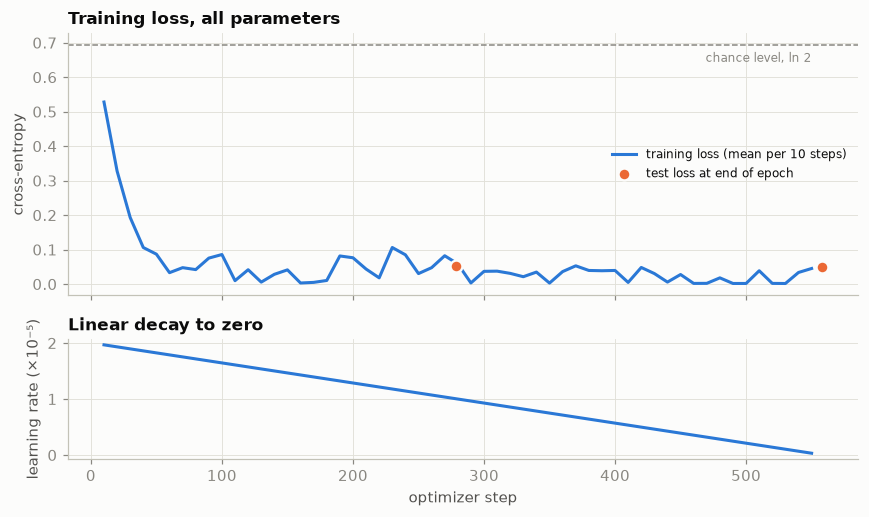

In [11]:
# Figure 2: training loss with the per-epoch evaluation loss, and the learning-rate schedule
train_log = history.dropna(subset=["loss"])
eval_log = history.dropna(subset=["eval_loss"])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 4.8), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax1.plot(train_log["step"], train_log["loss"], color=BLUE, label="training loss (mean per 10 steps)")
ax1.scatter(eval_log["step"], eval_log["eval_loss"], color=ORANGE, s=60, zorder=3, edgecolor=SURFACE, linewidth=1.5,
            label="test loss at end of epoch")
ax1.axhline(np.log(2), color=MUTED, linestyle="--", linewidth=1)
ax1.annotate("chance level, ln 2", xy=(train_log["step"].max(), np.log(2)), xytext=(0, -11), textcoords="offset points",
             ha="right", fontsize=8, color=MUTED)
ax1.set(ylabel="cross-entropy", title="Training loss, all parameters")
ax1.legend(loc="center right", fontsize=8)

ax2.plot(train_log["step"], train_log["learning_rate"] * 1e5, color=BLUE)
ax2.set(xlabel="optimizer step", ylabel="learning rate (×10⁻⁵)", title="Linear decay to zero")
fig.tight_layout()
fig.savefig("assets/4.1-training-curve.png")
plt.show()

**Reading the curve.**

- The loss starts near 0.53, already below the chance level of 0.693, and falls under 0.1 within about 50 steps, which is roughly 800 messages. After that the curve is noise around a very small number. Most of what this model will ever learn about spam, it learns in the first fifth of the first epoch.
- Compare with notebook 4, where the head-only loss was still drifting around 0.5 after its whole run. Part of that is the task (spam is easier than sentiment), part is that the optimizer here can move the features.
- **Loss and accuracy disagree about which epoch is better.** Test loss improves from 0.0534 to 0.0501 while test accuracy *drops* from 99.01% to 98.74%, a difference of three messages. Cross-entropy is a proper scoring rule and rewards being confidently right on the bulk of the data; accuracy only counts which side of 0.5 each message lands on. `load_best_model_at_end` selects on loss, so the epoch-2 checkpoint is the one evaluated below. Neither choice is wrong, but with differences this small, which checkpoint "wins" is close to arbitrary.

## 7. Evaluate the model

Evaluating the model is as simple as calling the evaluate method on the `trainer` object. This will run the model on the test set and compute the metrics we specified in the `compute_metrics` function.

In [12]:
# Show the performance of the model on the test set
# What do you think the evaluation accuracy will be?
trainer.evaluate()

{'eval_loss': 0.050100844353437424,
 'eval_accuracy': 0.9874439461883409,
 'eval_runtime': 1.5771,
 'eval_samples_per_second': 706.994,
 'eval_steps_per_second': 44.385,
 'epoch': 2.0}

### 7.1 Metrics that respect the imbalance

With spam as the positive class:

$$\text{precision} = \frac{TP}{TP + FP} \quad\text{(of the messages I flagged, how many were spam?)} \qquad \text{recall} = \frac{TP}{TP + FN} \quad\text{(of the spam, how much did I catch?)}$$

Neither involves $TN$, the huge count of correctly ignored ordinary messages that inflates accuracy. A single-number summary that uses all four cells and stays honest under imbalance is the **Matthews correlation coefficient**:

$$\mathrm{MCC} = \frac{TP\cdot TN - FP\cdot FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}} \in [-1, 1].$$

It is the Pearson correlation between predicted and true labels. The always-"not spam" classifier scores 0, not 0.87.

For a threshold-free comparison I use the **precision-recall curve** instead of ROC. With few positives, the false-positive *rate* stays tiny even when false positives outnumber true positives, so ROC curves look flattering. Precision does not have that problem.

In [13]:
from scipy.special import softmax

predictions = trainer.predict(tokenized_dataset["test"])
probs = softmax(predictions.predictions, axis=1)
bert_scores = probs[:, 1]
bert_preds = probs.argmax(axis=1)


def wilson_interval(p_hat, n, z=1.96):
    centre = p_hat + z**2 / (2 * n)
    half = z * np.sqrt(p_hat * (1 - p_hat) / n + z**2 / (4 * n**2))
    return (centre - half) / (1 + z**2 / n), (centre + half) / (1 + z**2 / n)


results.append(summarize("DistilBERT, full fine-tuning", y_test, bert_preds, trainable))

accuracy = (bert_preds == y_test).mean()
low, high = wilson_interval(accuracy, len(y_test))
print(f"fine-tuned DistilBERT accuracy: {accuracy:.4f}   95% Wilson interval [{low:.4f}, {high:.4f}]   (n = {len(y_test)})")
print(f"errors on {len(y_test)} test messages: "
      f"TF-IDF {(tfidf_preds != y_test).sum()}, linear probe {(probe_preds != y_test).sum()}, full fine-tuning {(bert_preds != y_test).sum()}")

show(results)

fine-tuned DistilBERT accuracy: 0.9874   95% Wilson interval [0.9790, 0.9925]   (n = 1115)
errors on 1115 test messages: TF-IDF 21, linear probe 8, full fine-tuning 14


,trainable parameters,accuracy,spam precision,spam recall,spam F1,MCC
model,,,,,,
always 'not spam',0,0.871,0.000,0.000,0.000,0.000
TF-IDF + logistic regression,"12,080",0.981,0.984,0.868,0.923,0.914
frozen DistilBERT + linear probe,769,0.993,0.993,0.951,0.972,0.968
"DistilBERT, full fine-tuning","66,955,010",0.987,0.964,0.938,0.951,0.944


### 7.2 Are these differences real?

All three models were scored on the *same* 1,115 messages, so the right comparison is paired. **McNemar's test** looks only at the messages where two models disagree. Let $b$ be the number that model A gets right and model B gets wrong, and $c$ the reverse. If the models were equally accurate, each disagreement would be a fair coin flip, so under the null hypothesis $b \sim \mathrm{Binomial}(b + c,\, \tfrac12)$. The exact two-sided p-value follows directly from that binomial.

In [14]:
from scipy.stats import binomtest


def mcnemar(name_a, preds_a, name_b, preds_b):
    a_only = int(((preds_a == y_test) & (preds_b != y_test)).sum())
    b_only = int(((preds_a != y_test) & (preds_b == y_test)).sum())
    p_value = binomtest(a_only, a_only + b_only, 0.5).pvalue if a_only + b_only else 1.0
    return {"model A": name_a, "model B": name_b, "only A correct": a_only, "only B correct": b_only, "exact p-value": round(p_value, 3)}


pd.DataFrame(
    [
        mcnemar("full fine-tuning", bert_preds, "TF-IDF + LR", tfidf_preds),
        mcnemar("linear probe", probe_preds, "TF-IDF + LR", tfidf_preds),
        mcnemar("linear probe", probe_preds, "full fine-tuning", bert_preds),
    ]
)

,model A,model B,only A correct,only B correct,exact p-value
0,full fine-tuning,TF-IDF + LR,13,6,0.167
1,linear probe,TF-IDF + LR,15,2,0.002
2,linear probe,full fine-tuning,6,0,0.031


### 7.3 Choosing a threshold from costs

`argmax` over two classes is the same as thresholding $p(\text{spam}\mid x)$ at 0.5. That is only optimal if both kinds of error cost the same, and for a spam filter they do not: a missed spam message is an annoyance, a real message sent to the spam folder can be a missed appointment.

Let $c_{FP}$ be the cost of blocking a real message and $c_{FN}$ the cost of letting spam through, and write $p = p(\text{spam} \mid x)$. The expected cost of each action is

$$\mathbb{E}[\text{cost} \mid \text{flag}] = (1 - p)\,c_{FP}, \qquad \mathbb{E}[\text{cost} \mid \text{allow}] = p\,c_{FN}.$$

Flagging is the better action exactly when $(1-p)\,c_{FP} < p\,c_{FN}$, which gives the Bayes-optimal threshold

$$p > t^* = \frac{c_{FP}}{c_{FP} + c_{FN}} .$$

Equal costs give $t^* = 0.5$. If blocking a real message is ten times worse than missing a spam, $t^* = 10/11 \approx 0.91$. This rule is only as good as the probabilities: it assumes $p$ is calibrated, which is one more reason calibration matters in practice.

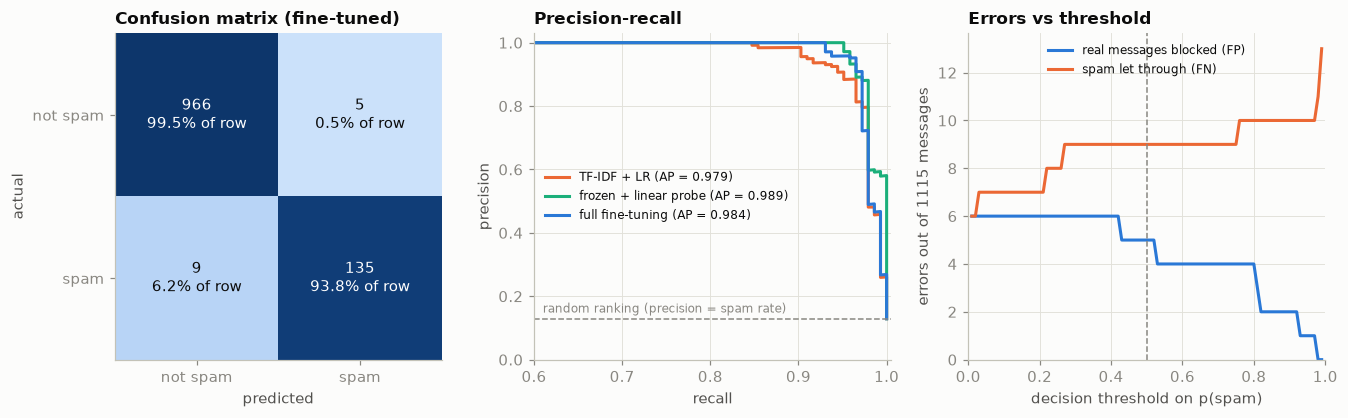

In [15]:
# Figure 3: confusion matrix, precision-recall against the baseline, and the threshold trade-off
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12.5, 3.9))

# (a) confusion matrix; colour by share of the row, because the two rows differ 6x in size
cm = confusion_matrix(y_test, bert_preds)
row_share = cm / cm.sum(axis=1, keepdims=True)
ax1.imshow(row_share, cmap=BLUES, vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax1.text(j, i, f"{cm[i, j]}\n{row_share[i, j]:.1%} of row", ha="center", va="center",
                 color="white" if row_share[i, j] > 0.55 else INK, fontsize=10)
ax1.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["not spam", "spam"], yticklabels=["not spam", "spam"],
        xlabel="predicted", ylabel="actual", title="Confusion matrix (fine-tuned)")
ax1.grid(False)

# (b) precision-recall curves
for scores, color, name in [
    (tfidf_scores, ORANGE, "TF-IDF + LR"),
    (probe_scores, AQUA, "frozen + linear probe"),
    (bert_scores, BLUE, "full fine-tuning"),
]:
    precision, recall, _ = precision_recall_curve(y_test, scores)
    ax2.plot(recall, precision, color=color, label=f"{name} (AP = {average_precision_score(y_test, scores):.3f})")
ax2.axhline(spam_rate, color=MUTED, linestyle="--", linewidth=1)
ax2.annotate("random ranking (precision = spam rate)", xy=(0.61, spam_rate), xytext=(0, 4), textcoords="offset points",
             fontsize=8, color=MUTED)
ax2.set(xlabel="recall", ylabel="precision", title="Precision-recall", xlim=(0.6, 1.005), ylim=(0, 1.03))
ax2.legend(loc="center left", fontsize=8)

# (c) the two error types as a function of the decision threshold
thresholds = np.linspace(0.01, 0.99, 99)
false_pos = [int(((bert_scores >= t) & (y_test == 0)).sum()) for t in thresholds]
false_neg = [int(((bert_scores < t) & (y_test == 1)).sum()) for t in thresholds]
ax3.plot(thresholds, false_pos, color=BLUE, label="real messages blocked (FP)")
ax3.plot(thresholds, false_neg, color=ORANGE, label="spam let through (FN)")
ax3.axvline(0.5, color=MUTED, linestyle="--", linewidth=1)
ax3.set(xlabel="decision threshold on p(spam)", ylabel=f"errors out of {len(y_test)} messages", title="Errors vs threshold",
        xlim=(0, 1), ylim=(0, None))
ax3.legend(loc="upper center", fontsize=8)

fig.tight_layout()
fig.savefig("assets/4.1-evaluation.png")
plt.show()

**What the numbers say. This is not the result I expected.**

- **Full fine-tuning reaches 98.7% accuracy, and it is not the best model in the table.** The frozen backbone with a 769-parameter linear probe makes 8 errors. Full fine-tuning of 67 million parameters makes 14. The TF-IDF baseline makes 21.
- **The probe's errors are a subset of the fine-tuned model's errors.** On the 6 messages where the two disagree, the probe is right every time. McNemar's exact test gives $p = 0.031$. I read that as suggestive and no more: it is one of three comparisons (a Bonferroni-corrected threshold would be 0.017), it comes from one seed, and the fine-tuned checkpoint was selected on this same test set. What I can say with confidence is the weaker statement: with this recipe, updating 67 million parameters gave **no advantage** over a linear read-out of frozen features that trains about 87,000 times fewer.
- **Against the bag of words, the gain is in recall, and only the probe's gain is statistically clear.** TF-IDF catches 87% of spam; the DistilBERT models catch 94% to 95%. The probe beats TF-IDF 15 to 2 on disagreements ($p = 0.002$). Full fine-tuning beats it 13 to 6 ($p = 0.17$), which on 1,115 messages is not enough to rule out chance. A 0.6-point accuracy gap looks like a win in a table and is not one under a paired test.
- **Why did fine-tuning not help?** The left panel of the next figure gives the reason: spam is already well separated in the *pre-trained* `[CLS]` space. There was little left for fine-tuning to fix, and two epochs at a single seed leave plenty of room for run-to-run variation. Peters et al. (2019) found that whether to freeze or fine-tune depends on how close the target task is to what pre-training already captured, and Zhou & Srikumar (2021) document cases where fine-tuning does not improve on the pre-trained representation. This looks like one of them.
- **The threshold cannot rescue the misses.** In the right panel, the number of real messages blocked falls to 1 or 0 as the threshold rises, as expected. But the missed-spam curve never drops below 6, even at a threshold of 0.01. Those messages receive a spam probability of essentially zero. They are errors of representation, not of calibration, and no decision rule applied to this model's scores will recover them.

## 8. What did fine-tuning do to the model?

Two measurements, using the "before" snapshot from section 4.1.

**Representation geometry.** I project the test-set `[CLS]` vectors to 2-D with PCA, once from the pre-trained backbone and once from the fine-tuned one. In [notebook 4](4-create-a-bert-sentiment-classifier.ipynb) the task direction was invisible to PCA because it carried about 1% of the variance. If fine-tuning reshapes the space around the task, that should change.

**Parameter movement.** For each block of weights I compute the relative change

$$\Delta_{\text{rel}} = \frac{\lVert \theta^{\text{fine-tuned}} - \theta^{(0)} \rVert_2}{\lVert \theta^{(0)} \rVert_2}.$$

Merchant et al. (2020) found that fine-tuning BERT mainly changes the top layers and leaves the lower ones close to their pre-trained state. This checks whether my run agrees.

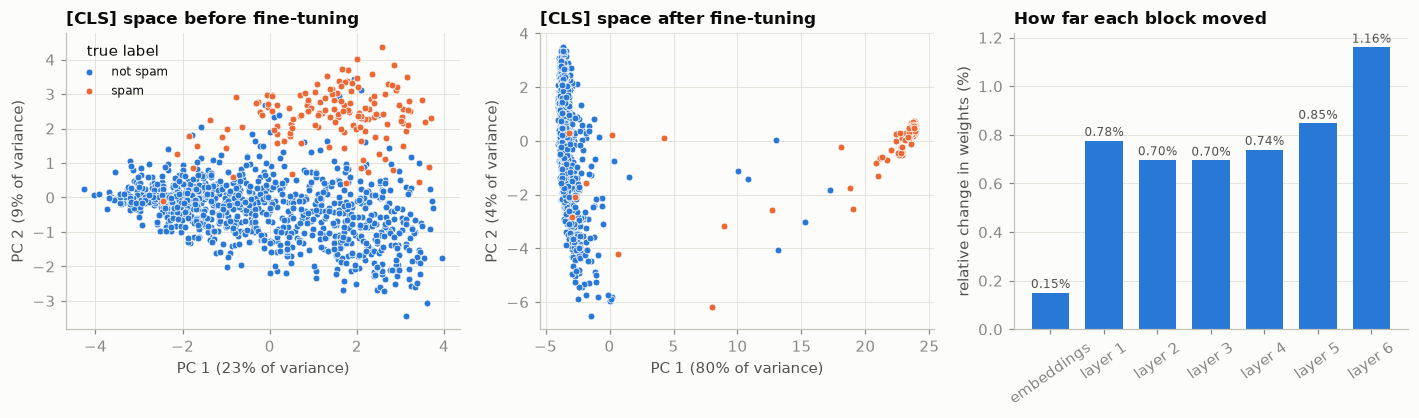

In [16]:
from sklearn.decomposition import PCA

features_after = cls_features(tokenized_dataset["test"])

# Relative parameter change per block (the head is excluded: it started from random values)
final_state = {name: p.detach().cpu() for name, p in model.named_parameters()}
groups = {"embeddings": "distilbert.embeddings."}
groups.update({f"layer {i + 1}": f"distilbert.transformer.layer.{i}." for i in range(6)})


def relative_change(prefix):
    names = [n for n in final_state if n.startswith(prefix)]
    moved = sum(((final_state[n] - initial_state[n]) ** 2).sum() for n in names)
    size = sum((initial_state[n] ** 2).sum() for n in names)
    return float(torch.sqrt(moved / size))


drift = pd.Series({name: relative_change(prefix) for name, prefix in groups.items()})

# Figure 4
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, feats, title in [
    (axes[0], features_before["test"], "[CLS] space before fine-tuning"),
    (axes[1], features_after, "[CLS] space after fine-tuning"),
]:
    pca = PCA(n_components=2, random_state=0).fit(feats)
    proj = pca.transform(feats)
    for cls, color, name in [(0, BLUE, "not spam"), (1, ORANGE, "spam")]:
        pts = proj[y_test == cls]
        ax.scatter(pts[:, 0], pts[:, 1], s=20, color=color, edgecolor=SURFACE, linewidth=0.5, label=name)
    ax.set(
        xlabel=f"PC 1 ({pca.explained_variance_ratio_[0]:.0%} of variance)",
        ylabel=f"PC 2 ({pca.explained_variance_ratio_[1]:.0%} of variance)",
        title=title,
    )
axes[0].legend(loc="best", fontsize=8, title="true label")

bars = axes[2].bar(drift.index, drift.values * 100, color=BLUE, width=0.7)
for bar, v in zip(bars, drift.values):
    axes[2].annotate(f"{v:.2%}", xy=(bar.get_x() + bar.get_width() / 2, v * 100), xytext=(0, 3),
                     textcoords="offset points", ha="center", fontsize=8, color=SECONDARY)
axes[2].set(ylabel="relative change in weights (%)", title="How far each block moved")
axes[2].tick_params(axis="x", labelrotation=35)
axes[2].grid(axis="x", visible=False)

fig.tight_layout()
fig.savefig("assets/4.1-before-after.png")
plt.show()

**Three observations.**

**1. Spam was visible before any training.** In the left panel the pre-trained backbone already places most spam in its own region of the top two principal components. Contrast that with [notebook 4](4-create-a-bert-sentiment-classifier.ipynb), where sentiment was invisible in the same plot and lived in a direction with about 1% of the variance. Spam differs from ordinary messages in register and vocabulary (capital letters, phone numbers, prize language), and that kind of surface difference is exactly what a language model's dominant directions encode. Sentiment is a subtler property of the same kind of text. This is why the linear probe is so strong here.

**2. Fine-tuning collapsed the space onto the task.** After fine-tuning, the first principal component alone explains 80% of the variance, up from 23%, and the test set sits in two tight clusters at opposite ends of it. The model has spent its representational budget on one question. That is what makes the classifier confident, and it is also what Kumar et al. (2022) warn about (in vision experiments): fine-tuning can distort pre-trained features, which helps in-distribution and can hurt out-of-distribution. A representation that only knows "spam or not" is of little use for anything else.

**3. It took a change of about 1% in the weights.** No block moved by more than 1.2% in relative norm. The top layer moved most (1.16%) and the embeddings least (0.15%), which agrees with Merchant et al. (2020) that fine-tuning primarily affects the top of the network. The pattern is not cleanly monotone, though: layer 1 moved slightly more than layers 2 to 4, and I do not have an explanation for that from a single run.

The combination of 2 and 3 is the striking part. A tiny displacement in parameter space produces a complete reorganization of the output space. It is also a hint that the update itself might have very low intrinsic dimension (Aghajanyan et al., 2020), which is the premise behind LoRA in the next notebook.

## 9. View the results

Let's look at a few examples.

In [17]:
# Make a dataframe with the predictions and the text and the labels
items_for_manual_review = tokenized_dataset["test"].select(
    [0, 1, 22, 31, 43, 292, 448, 487]
)

results_review = trainer.predict(items_for_manual_review)
df = pd.DataFrame(
    {
        "sms": [item["sms"] for item in items_for_manual_review],
        "predictions": results_review.predictions.argmax(axis=1),
        "labels": results_review.label_ids,
    }
)
# Show all the cell
pd.set_option("display.max_colwidth", None)
df

,sms,predictions,labels
0,Yup... Hey then one day on fri we can ask miwa and jiayin take leave go karaoke \n,0,0
1,Happy new years melody!\n,0,0
2,PRIVATE! Your 2003 Account Statement for shows 800 un-redeemed S. I. M. points. Call 08715203652 Identifier Code: 42810 Expires 29/10/0\n,1,1
3,URGENT! We are trying to contact U. Todays draw shows that you have won a £800 prize GUARANTEED. Call 09050003091 from land line. Claim C52. Valid 12hrs only\n,1,1
4,I had askd u a question some hours before. Its answer\n,0,0
5,"SMS. ac JSco: Energy is high, but u may not know where 2channel it. 2day ur leadership skills r strong. Psychic? Reply ANS w/question. End? Reply END JSCO\n",0,1
6,"Yun ah.the ubi one say if ü wan call by tomorrow.call 67441233 look for irene.ere only got bus8,22,65,61,66,382. Ubi cres,ubi tech park.6ph for 1st 5wkg days.èn\n",1,0
7,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola and walk out a winner\n,0,1


### Every mistake on the test set

With this few errors there is no need to sample. Here are all of them, with the model's spam probability.

In [18]:
errors = pd.DataFrame(
    {
        "sms": [t.strip() for t in test_text],
        "label": np.where(y_test == 1, "spam", "not spam"),
        "predicted": np.where(bert_preds == 1, "spam", "not spam"),
        "p(spam)": bert_scores.round(3),
        "TF-IDF also wrong": tfidf_preds != y_test,
    }
)[bert_preds != y_test].sort_values("p(spam)")
errors

,sms,label,predicted,p(spam),TF-IDF also wrong
250,ROMCAPspam Everyone around should be responding well to your presence since you are so warm and outgoing. You are bringing in a real breath of sunshine.,spam,not spam,0.001,True
364,Hello. We need some posh birds and chaps to user trial prods for champneys. Can i put you down? I need your address and dob asap. Ta r,spam,not spam,0.001,True
526,Filthy stories and GIRLS waiting for your,spam,not spam,0.001,True
274,"Hi this is Amy, we will be sending you a free phone number in a couple of days, which will give you an access to all the adult parties...",spam,not spam,0.002,True
816,"Will u meet ur dream partner soon? Is ur career off 2 a flyng start? 2 find out free, txt HORO followed by ur star sign, e. g. HORO ARIES",spam,not spam,0.004,True
492,This message is brought to you by GMW Ltd. and is not connected to the,spam,not spam,0.006,True
292,"SMS. ac JSco: Energy is high, but u may not know where 2channel it. 2day ur leadership skills r strong. Psychic? Reply ANS w/question. End? Reply END JSCO",spam,not spam,0.028,True
487,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola and walk out a winner,spam,not spam,0.219,True
753,Welcome! Please reply with your AGE and GENDER to begin. e.g 24M,spam,not spam,0.265,False
803,"Hi, Mobile no. &lt;#&gt; has added you in their contact list on www.fullonsms.com It s a great place to send free sms to people For more visit fullonsms.com",not spam,spam,0.522,False


**Reading the errors.**

- **Nine spam messages were missed, and the TF-IDF model missed eight of the same nine.** When two models with completely different inductive biases fail on the same inputs, the difficulty is in the data, not in either model. These messages lack every usual marker: no prize, no "FREE", no short code. Some read like a note from a friend ("We need some posh birds and chaps..."), some are chatty horoscope text, and a few are fragments cut off mid-sentence. For one or two of them I would not be confident of the label myself.
- **Five ordinary messages were flagged as spam, and TF-IDF got all five right.** Here the fine-tuned model has over-generalized. A broadband installation notice, a sign-up notification and step-by-step instructions containing numbers are all written in a transactional register, and the model has learned "transactional means spam". A bag of words, which keys on specific tokens, is not fooled.
- The two error types have different causes and would need different fixes: more varied spam examples for the first, more legitimate transactional messages for the second. An overall accuracy number hides that entirely.

## 10. How spam and abuse classifiers are built in production

The pre-train-then-fine-tune recipe of this notebook is the paradigm the BERT paper introduced, with its claim that a pre-trained model "can be fine-tuned with just one additional output layer" for a wide range of tasks (Devlin et al., 2018). Production systems use it heavily, and the public write-ups are most interesting for what they add around it.

**Meta: pre-train once, fine-tune with few labels.** Meta's 2020 account of its hate-speech systems describes exactly this recipe: self-supervised pre-training of XLM-R / RoBERTa-style models, followed by fine-tuning on "a much smaller amount of labeled data for the specific task". They report that in Q1 2020 AI systems proactively detected 88.8% of the hate speech that was removed. The reason for the recipe is the one in section 1.1: violating content is rare, so labels for it are scarce and expensive.

**OpenAI: the model is the easy part.** Markov et al. (2022) describe building a real-world content moderation classifier, and most of the paper is not about architecture. It is about taxonomy design, label quality control, and **active learning to find rare positive examples**. That is the industrial version of the class-imbalance problem in this notebook: when positives are a fraction of a percent of traffic, random sampling for labelling wastes almost all of the budget.

**Gmail: scale and adversaries.** Google reported in 2019 that Gmail's existing machine-learning filters already blocked more than 99.9% of spam, phishing and malware, and that new TensorFlow-based models were blocking around 100 million *additional* spam messages every day. That post is not about transformers, and I cite it for the framing: at 99.9% the whole game is the last tenth of a percent, the same regime as the handful of errors analysed in section 9. The follow-up is more instructive. In 2023 Google replaced the text vectorizer in Gmail's spam classifier with **RETVec** (Bursztein et al., 2023), a small character-level encoder built to survive typos, homoglyphs and deliberate obfuscation. They report a 38% improvement in spam detection rate, 19.4% fewer false positives and 83% lower TPU usage. A WordPiece tokenizer like the one used here is easy to attack: writing "fr3e" or "F R E E" changes the token sequence completely.

**Google Jigsaw: the same lesson for toxicity.** The current Perspective API is built on a single multilingual, byte-level Charformer (Lees et al., 2022), chosen for the same robustness reasons.

**LinkedIn: classification inside search.** LinkedIn's DeText framework (Guo et al., 2020) runs BERT-family models in production for search tasks including query intent classification, validated with online A/B tests instead of offline accuracy alone.

**What I take from these.**

1. **Baselines and cost decide deployment.** Gmail did not replace its filters with the largest available model. RETVec won partly by being *cheaper*. The TF-IDF row in my table is the kind of evidence that argument needs.
2. **False positives are the expensive error,** and thresholds are set from costs as in section 7.3, not left at 0.5.
3. **The data is adversarial and non-stationary.** My test set is an i.i.d. sample from 2011. Production spam is neither i.i.d. nor from 2011.
4. **Rare positives make labelling the bottleneck,** which is why pre-training and active learning matter more in practice than the choice between two fine-tuning recipes.

## 11. Limitations, and what comes next

- **The test set doubles as the validation set.** The exercise evaluates on the test split after each epoch and `load_best_model_at_end` keeps the better checkpoint. That is model selection on test data. With two checkpoints the optimism is small, but the clean protocol is a three-way split, and I would not report these numbers in a paper as they stand.
- **One seed.** Fine-tuning results vary across random seeds (Mosbach et al., 2020). The gap between the fine-tuned model and the baselines here is a handful of messages. Notebook 4.2 repeats its comparison over several seeds for this reason.
- **A 2011 dataset.** These messages predate smartphones' spam ecosystem and every modern evasion technique. Random splitting also puts near-duplicate spam templates in both train and test, which flatters every model in the table, the baseline included. A time-based split would be a harder and more realistic test.
- **No adversary.** Real spam is written by people who are trying to defeat the classifier. Section 10 comes back to this.
- **Cost is not in the table.** The fine-tuned model is about 67M parameters and needs a GPU to be fast. The TF-IDF model fits in a few megabytes and runs anywhere. Whether a handful of extra correct messages per thousand is worth that depends entirely on the application.

**Next:** [4.2 - Linear probe vs full fine-tuning vs LoRA](4.2-linear-probe-vs-full-fine-tuning-vs-lora.ipynb) puts the frozen head from notebook 4 and the full fine-tuning from this notebook on the *same* dataset, over several seeds, and adds LoRA as the point in between.

## References

**Fine-tuning**
- Devlin et al. (2018). *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding.* [arXiv:1810.04805](https://arxiv.org/abs/1810.04805)
- Sanh, Debut, Chaumond & Wolf (2019). *DistilBERT, a distilled version of BERT: smaller, faster, cheaper and lighter.* [arXiv:1910.01108](https://arxiv.org/abs/1910.01108)
- Howard & Ruder (2018). *Universal Language Model Fine-tuning for Text Classification.* [arXiv:1801.06146](https://arxiv.org/abs/1801.06146)
- Peters, Ruder & Smith (2019). *To Tune or Not to Tune? Adapting Pretrained Representations to Diverse Tasks.* [arXiv:1903.05987](https://arxiv.org/abs/1903.05987)
- Mosbach, Andriushchenko & Klakow (2020). *On the Stability of Fine-tuning BERT: Misconceptions, Explanations, and Strong Baselines.* [arXiv:2006.04884](https://arxiv.org/abs/2006.04884)
- Kirkpatrick et al. (2016). *Overcoming catastrophic forgetting in neural networks.* [arXiv:1612.00796](https://arxiv.org/abs/1612.00796)

**What fine-tuning changes**
- Merchant, Rahimtoroghi, Pavlick & Tenney (2020). *What Happens To BERT Embeddings During Fine-tuning?* [arXiv:2004.14448](https://arxiv.org/abs/2004.14448)
- Zhou & Srikumar (2021). *A Closer Look at How Fine-tuning Changes BERT.* [arXiv:2106.14282](https://arxiv.org/abs/2106.14282)
- Kumar et al. (2022). *Fine-Tuning can Distort Pretrained Features and Underperform Out-of-Distribution.* [arXiv:2202.10054](https://arxiv.org/abs/2202.10054)
- Aghajanyan, Zettlemoyer & Gupta (2020). *Intrinsic Dimensionality Explains the Effectiveness of Language Model Fine-Tuning.* [arXiv:2012.13255](https://arxiv.org/abs/2012.13255)

**Data**
- Almeida, Gómez Hidalgo & Yamakami (2011). *Contributions to the Study of SMS Spam Filtering: New Collection and Results.* ACM DocEng 2011. [doi:10.1145/2034691.2034742](https://doi.org/10.1145/2034691.2034742)

**Industry**
- Meta AI (2020). *AI advances to better detect hate speech.* [ai.meta.com](https://ai.meta.com/blog/ai-advances-to-better-detect-hate-speech/)
- Markov et al., OpenAI (2022). *A Holistic Approach to Undesired Content Detection in the Real World.* [arXiv:2208.03274](https://arxiv.org/abs/2208.03274)
- Kumaran, Google (2019). *Spam does not bring us joy: ridding Gmail of 100 million more spam messages with TensorFlow.* [workspace.google.com](https://workspace.google.com/blog/product-announcements/ridding-gmail-of-100-million-more-spam-messages-with-tensorflow)
- Bursztein & Zhang, Google (2023). *Improving Text Classification Resilience and Efficiency with RETVec.* [security.googleblog.com](https://security.googleblog.com/2023/11/improving-text-classification.html); paper: [arXiv:2302.09207](https://arxiv.org/abs/2302.09207)
- Lees et al., Google Jigsaw (2022). *A New Generation of Perspective API: Efficient Multilingual Character-level Transformers.* [arXiv:2202.11176](https://arxiv.org/abs/2202.11176)
- Guo et al., LinkedIn (2020). *DeText: A Deep Text Ranking Framework with BERT.* [arXiv:2008.02460](https://arxiv.org/abs/2008.02460)

## End of the Exercise

Great work! Congrats on making it to the end of the exercise!